# US

APIキーを読み込みました。データを取得中...
取得完了！グラフを描画します。


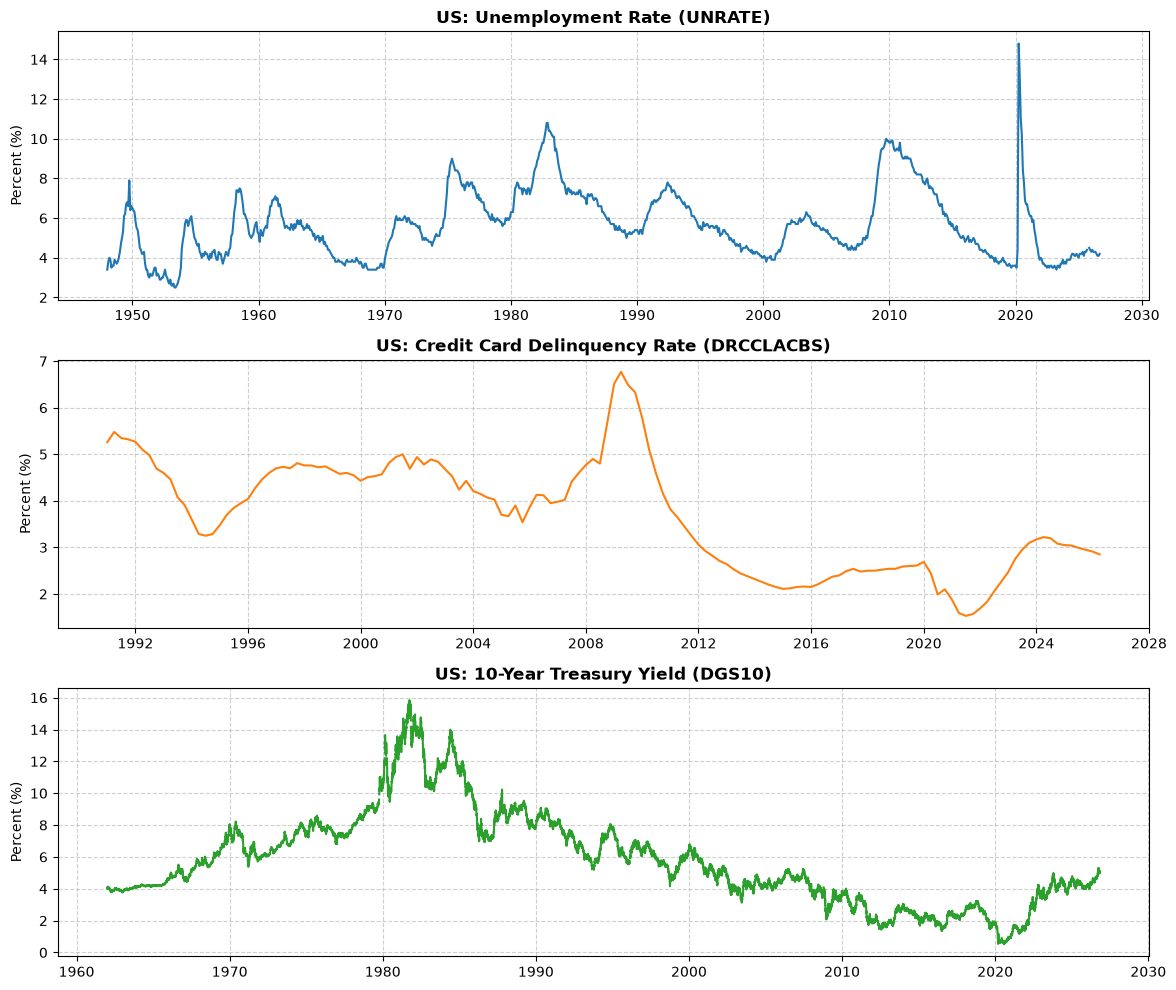

In [7]:
import os
from fredapi import Fred
import matplotlib.pyplot as plt

# .bashrc に定義された環境変数から API キーを取得
api_key = os.environ.get('FRED_API_KEY')

if not api_key:
    print("⚠️ エラー: 'FRED_API_KEY' が環境変数に見つかりません。")
    print("Jupyter Labを起動しているターミナルで `export FRED_API_KEY='あなたのキー'` を実行するか、カーネルを再起動してください。")
else:
    print("APIキーを読み込みました。データを取得中...")
    
    # FREDクライアントの初期化
    fred = Fred(api_key=api_key)

    # データの取得
    unrate = fred.get_series('UNRATE')
    delinquency = fred.get_series('DRCCLACBS')
    treasury = fred.get_series('DGS10')

    print("取得完了！グラフを描画します。")

    # グラフ描画（3段のサブプロット）
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=False)

    axes[0].plot(unrate.index, unrate.values, color='#1f77b4', lw=1.5)
    axes[0].set_title('US: Unemployment Rate (UNRATE)', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Percent (%)')
    axes[0].grid(True, linestyle='--', alpha=0.6)

    axes[1].plot(delinquency.index, delinquency.values, color='#ff7f0e', lw=1.5)
    axes[1].set_title('US: Credit Card Delinquency Rate (DRCCLACBS)', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Percent (%)')
    axes[1].grid(True, linestyle='--', alpha=0.6)

    axes[2].plot(treasury.index, treasury.values, color='#2ca02c', lw=1.5)
    axes[2].set_title('US: 10-Year Treasury Yield (DGS10)', fontsize=12, fontweight='bold')
    axes[2].set_ylabel('Percent (%)')
    axes[2].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

APIキーを読み込みました。データを取得中...
取得完了！グラフを描画します。


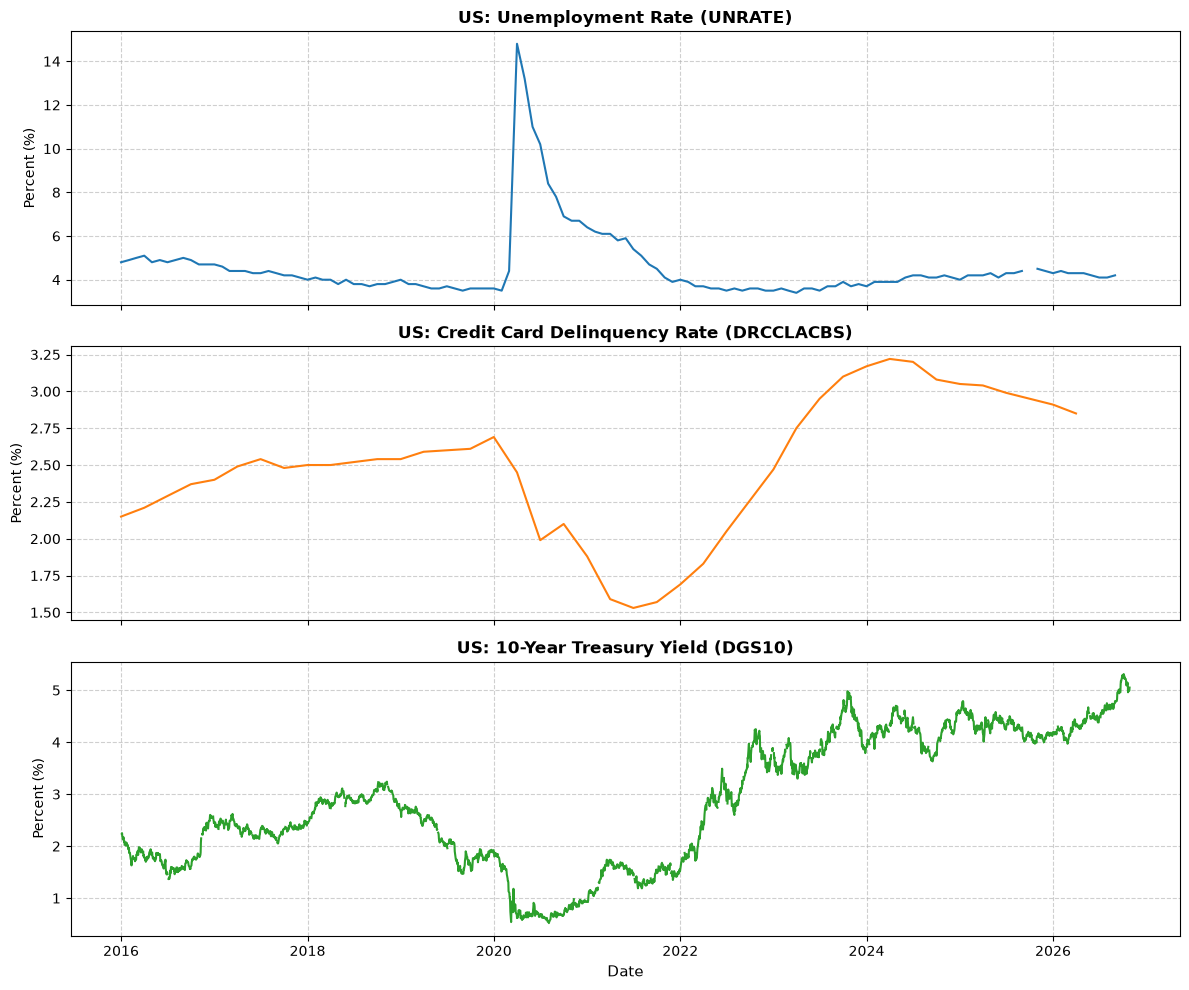

In [8]:
import os
from fredapi import Fred
import matplotlib.pyplot as plt

# 環境変数からAPIキーを取得
api_key = os.environ.get('FRED_API_KEY')

if not api_key:
    print("⚠️ エラー: 'FRED_API_KEY' が環境変数に見つかりません。")
    print("Jupyter Labを起動しているターミナルで `export FRED_API_KEY='あなたのキー'` を実行するか、カーネルを再起動してください。")
else:
    print("APIキーを読み込みました。データを取得中...")
    
    try:
        fred = Fred(api_key=api_key)

        # 取得したい指標の定義（辞書形式で名前とティッカーを管理）
        us_indicators = {
            'Unemployment Rate (UNRATE)': 'UNRATE',
            'Credit Card Delinquency Rate (DRCCLACBS)': 'DRCCLACBS',
            '10-Year Treasury Yield (DGS10)': 'DGS10'
        }

        # データの取得と直近10年への絞り込み（オプション）
        data = {}
        for name, ticker in us_indicators.items():
            series = fred.get_series(ticker)
            # 直近のトレンドを見やすくするため、2016年以降に絞る（全期間見たい場合はこの行をコメントアウト）
            series = series.loc['2016-01-01':]
            data[name] = series

        print("取得完了！グラフを描画します。")

        # グラフ描画（3段のサブプロット / sharex=Trueで軸を連動）
        fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
        colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

        for i, (name, series) in enumerate(data.items()):
            axes[i].plot(series.index, series.values, color=colors[i], lw=1.5)
            axes[i].set_title(f'US: {name}', fontsize=12, fontweight='bold')
            axes[i].set_ylabel('Percent (%)')
            axes[i].grid(True, linestyle='--', alpha=0.6)

        # 最下層のグラフにだけX軸のラベルを明確にする
        axes[-1].set_xlabel('Date', fontsize=11)

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"⚠️ データ取得または描画中にエラーが発生しました: {e}")

# Singapore

APIキーを読み込みました。シンガポールのデータを取得中...
⚠️ ティッカー CCUSMA01SGM659N の取得に失敗しました: Bad Request.  The series does not exist.
取得完了！グラフを描画します。


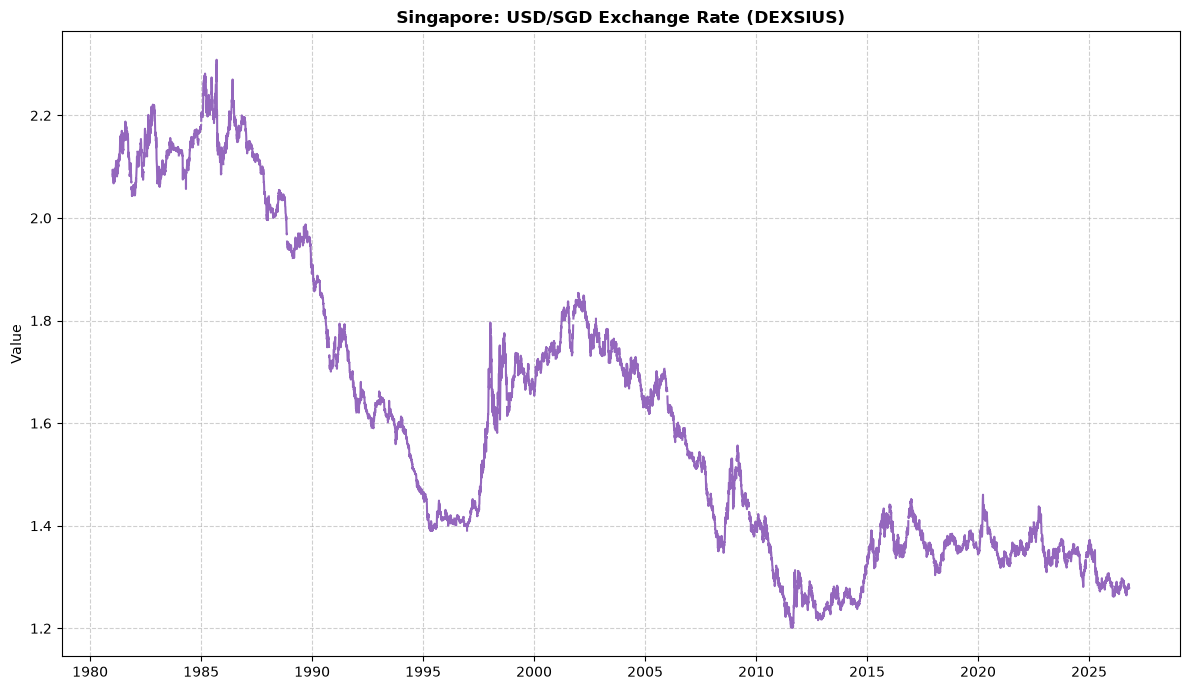

In [9]:
import os
from fredapi import Fred
import matplotlib.pyplot as plt

# 環境変数からAPIキーを取得
api_key = os.environ.get('FRED_API_KEY')

if not api_key:
    print("⚠️ エラー: 'FRED_API_KEY' が環境変数に見つかりません。")
else:
    print("APIキーを読み込みました。シンガポールのデータを取得中...")
    
    fred = Fred(api_key=api_key)

    # 現在もFREDで確実に対象が存在するシンガポールの主要ティッカー
    # - DEXSIUS: 米ドル/シンガポールドル（USD/SGD スポット為替レート）
    # - CCUSMA01SGM659N: シンガポールの消費者物価指数（CPI）
    sg_tickers = {
        'USD/SGD Exchange Rate (DEXSIUS)': 'DEXSIUS',
        'Consumer Price Index (CCUSMA01SGM659N)': 'CCUSMA01SGM659N'
    }

    sg_data = {}
    for name, ticker in sg_tickers.items():
        try:
            sg_data[name] = fred.get_series(ticker)
        except Exception as e:
            print(f"⚠️ ティッカー {ticker} の取得に失敗しました: {e}")

    if sg_data:
        print("取得完了！グラフを描画します。")

        # グラフ描画（2段のサブプロット）
        fig, axes = plt.subplots(len(sg_data), 1, figsize=(12, 7), sharex=False)
        if len(sg_data) == 1:
            axes = [axes]
            
        colors = ['#9467bd', '#8c564b']

        for i, (name, series) in enumerate(sg_data.items()):
            axes[i].plot(series.index, series.values, color=colors[i], lw=1.5)
            axes[i].set_title(f'Singapore: {name}', fontsize=12, fontweight='bold')
            axes[i].set_ylabel('Value')
            axes[i].grid(True, linestyle='--', alpha=0.6)

        plt.tight_layout()
        plt.show()
    else:
        print("有効なデータが取得できませんでした。")

Yahoo Financeから金属・暗号資産のデータを取得中...


[*********************100%***********************]  6 of 6 completed


取得完了！グラフを描画します。


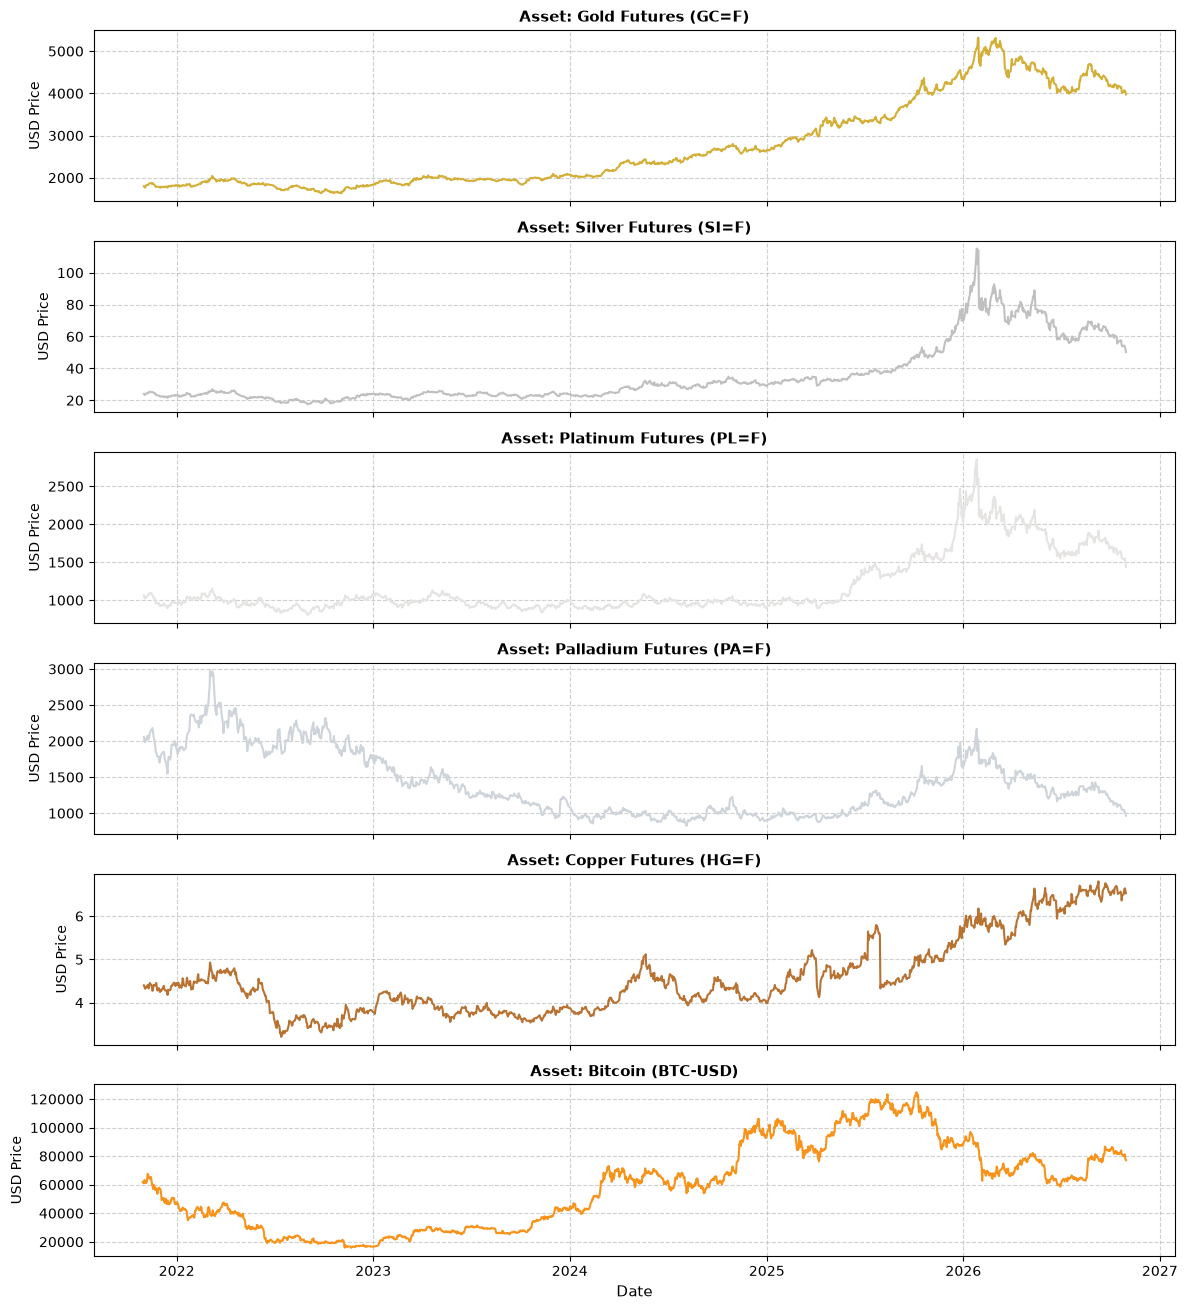

In [10]:
import yfinance as yf
import matplotlib.pyplot as plt

# 貴金属、工業用金属、暗号資産のティッカー設定
tickers = {
    'Gold Futures (GC=F)': 'GC=F',
    'Silver Futures (SI=F)': 'SI=F',
    'Platinum Futures (PL=F)': 'PL=F',
    'Palladium Futures (PA=F)': 'PA=F',
    'Copper Futures (HG=F)': 'HG=F',
    'Bitcoin (BTC-USD)': 'BTC-USD'
}

print("Yahoo Financeから金属・暗号資産のデータを取得中...")

# データの取得（ティッカーのリストをそのまま渡す）
ticker_list = list(tickers.values())
data = yf.download(ticker_list, period='5y')['Close']

print("取得完了！グラフを描画します。")

# グラフの描画（資産の数に合わせて動的にサブプロットを生成）
n = len(tickers)
fig, axes = plt.subplots(n, 1, figsize=(12, 2.2 * n), sharex=True)
if n == 1:
    axes = [axes]

# 資産ごとのカラーパレット
colors = ['#d4af37', '#c0c0c0', '#e5e4e2', '#ced4da', '#b87333', '#f7931a']

for i, (name, ticker) in enumerate(tickers.items()):
    # ティッカー名がカラムに存在する場合のみ安全にプロット
    if ticker in data.columns:
        series = data[ticker].dropna()
        axes[i].plot(series.index, series.values, color=colors[i % len(colors)], lw=1.5)
        axes[i].set_title(f'Asset: {name}', fontsize=11, fontweight='bold')
        axes[i].set_ylabel('USD Price')
        axes[i].grid(True, linestyle='--', alpha=0.6)
    else:
        axes[i].set_title(f'Asset: {name} (データなし)', fontsize=11, fontweight='bold')

# 最下層のグラフにだけX軸のラベルを表示
axes[-1].set_xlabel('Date', fontsize=11)

plt.tight_layout()
plt.show()

[*********************100%***********************]  3 of 3 completed

Yahoo FinanceからAI・テック市場の警戒データを取得中...
取得完了！グラフを描画します。


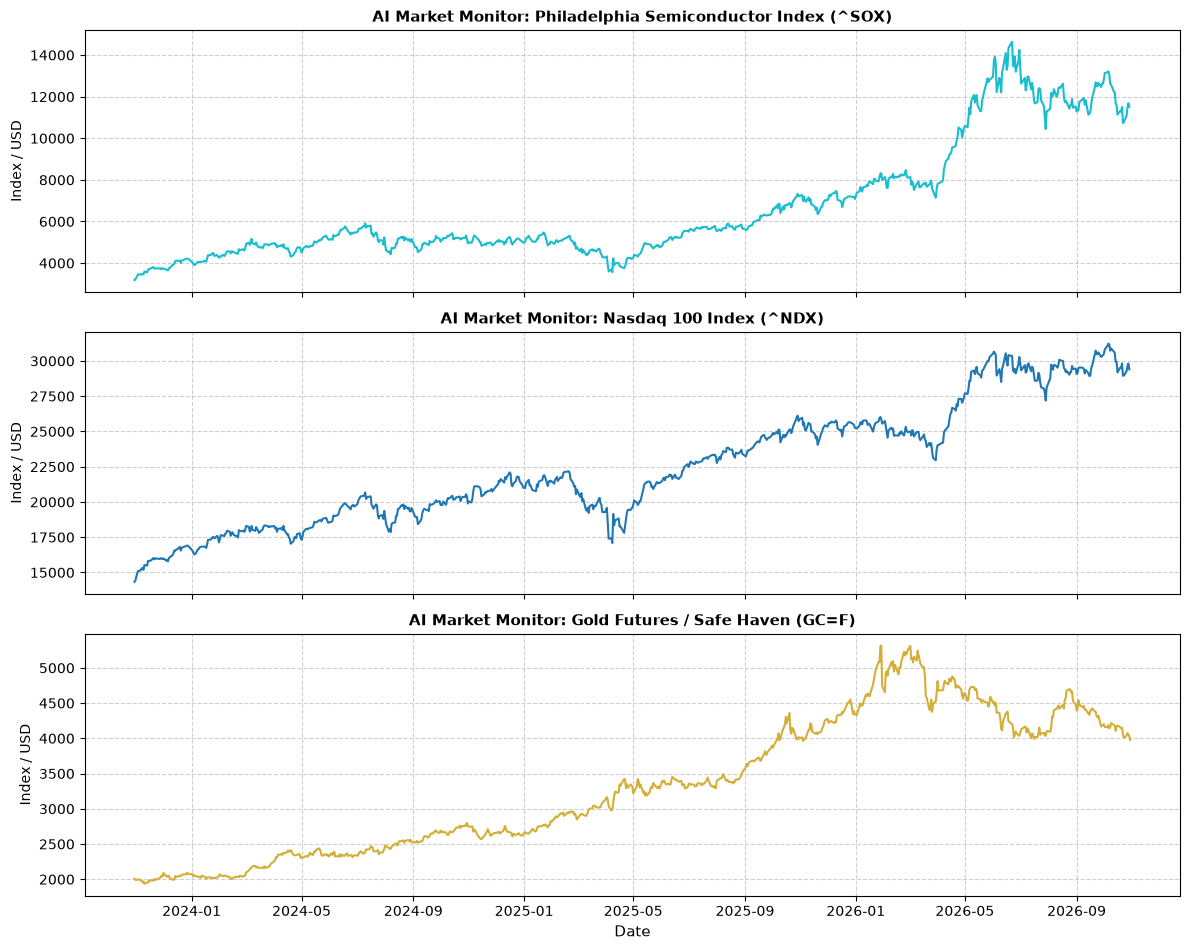

In [11]:
import yfinance as yf
import matplotlib.pyplot as plt

# AIバブル・テック市場の動向とリスクシグナルを追跡するティッカー
# - ^SOX : フィラデルフィア半導体株指数（AIハードウェア・GPU需要のバロメーター）
# - ^NDX : NASDAQ 100 指数（AIをけん引するメガキャップ・テック全体の動向）
# - GC=F : 金（ゴールド）先物（市場に警戒感やリスクオフが走った際の避難先）
ai_risk_tickers = {
    'Philadelphia Semiconductor Index (^SOX)': '^SOX',
    'Nasdaq 100 Index (^NDX)': '^NDX',
    'Gold Futures / Safe Haven (GC=F)': 'GC=F'
}

print("Yahoo FinanceからAI・テック市場の警戒データを取得中...")

# データの取得（直近3年分でトレンドの変化を捉える）
ticker_list = list(ai_risk_tickers.values())
data = yf.download(ticker_list, period='3y')['Close']

print("取得完了！グラフを描画します。")

# グラフの描画（3段のサブプロット）
n = len(ai_risk_tickers)
fig, axes = plt.subplots(n, 1, figsize=(12, 3.2 * n), sharex=True)
if n == 1:
    axes = [axes]

# カラーパレット（シアン、青、ゴールド）
colors = ['#17becf', '#1f77b4', '#d4af37']

for i, (name, ticker) in enumerate(ai_risk_tickers.items()):
    if ticker in data.columns:
        series = data[ticker].dropna()
        axes[i].plot(series.index, series.values, color=colors[i], lw=1.5)
        axes[i].set_title(f'AI Market Monitor: {name}', fontsize=11, fontweight='bold')
        axes[i].set_ylabel('Index / USD')
        axes[i].grid(True, linestyle='--', alpha=0.6)
    else:
        axes[i].set_title(f'Monitor: {name} (データなし)', fontsize=11, fontweight='bold')

# 最下層のグラフにだけX軸のラベルを表示
axes[-1].set_xlabel('Date', fontsize=11)

plt.tight_layout()
plt.show()

[*********************100%***********************]  3 of 3 completed

Yahoo Financeからオラクルおよび信用リスクデータを取得中...
取得完了！グラフを描画します。


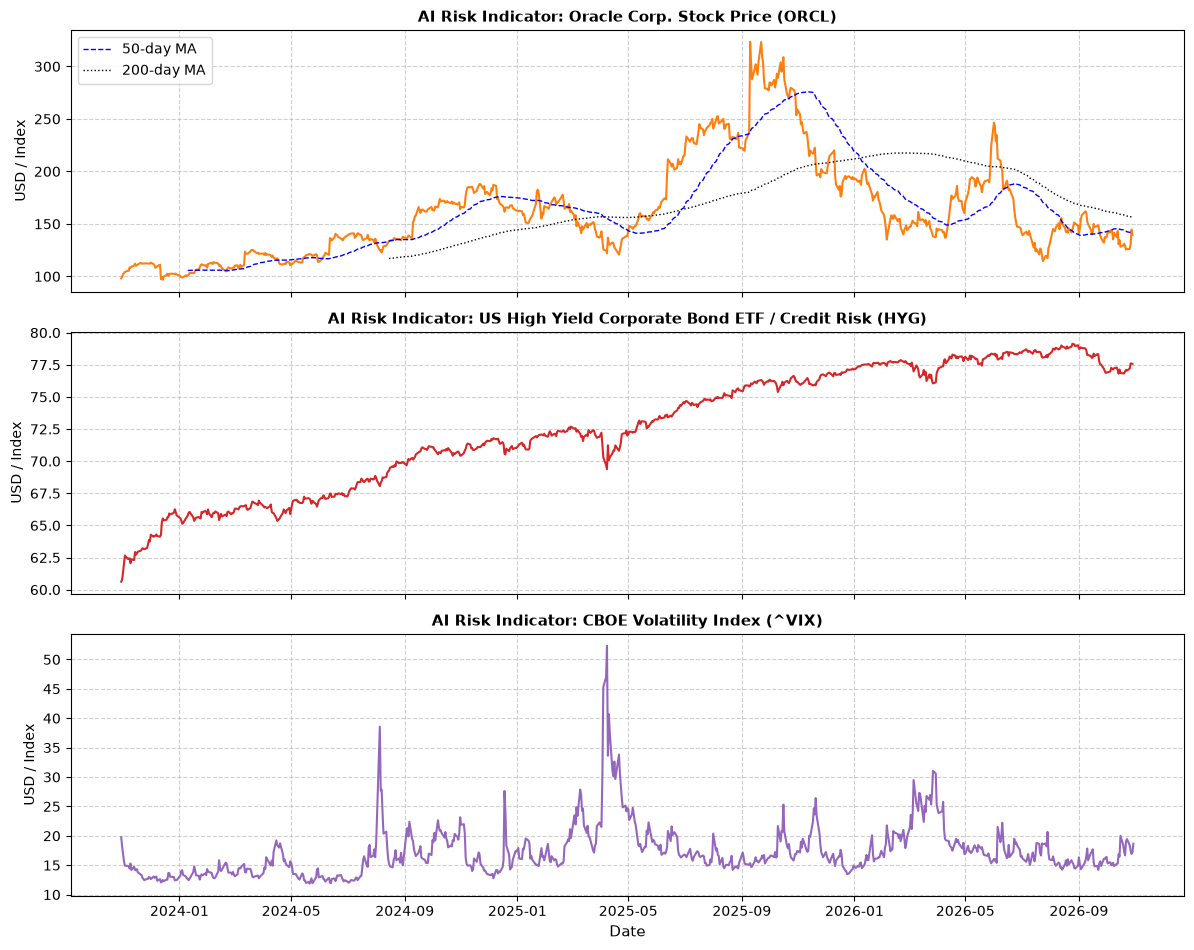

In [12]:
import yfinance as yf
import matplotlib.pyplot as plt

# Oracle（AIクラウドインフラの代表）と市場の信用・ボラティリティ指標
# - ORCL    : オラクル株価（巨額AIデータセンター投資の当事者）
# - ORCL261218C00200000 などのボラティリティ代理、または株価の200日移動平均乖離率
# - HYG     : ハイイールド社債ETF（企業の信用リスク・デフォルト懸念のバロメーター）
# - ^VIX    : VIX指数（市場の恐怖指数・ボラティリティ）
orcl_risk_tickers = {
    'Oracle Corp. Stock Price (ORCL)': 'ORCL',
    'US High Yield Corporate Bond ETF / Credit Risk (HYG)': 'HYG',
    'CBOE Volatility Index (^VIX)': '^VIX'
}

print("Yahoo Financeからオラクルおよび信用リスクデータを取得中...")

ticker_list = list(orcl_risk_tickers.values())
data = yf.download(ticker_list, period='3y')['Close']

print("取得完了！グラフを描画します。")

# グラフの描画（3段のサブプロット）
n = len(orcl_risk_tickers)
fig, axes = plt.subplots(n, 1, figsize=(12, 3.2 * n), sharex=True)
if n == 1:
    axes = [axes]

colors = ['#ff7f0e', '#d62728', '#9467bd']

for i, (name, ticker) in enumerate(orcl_risk_tickers.items()):
    if ticker in data.columns:
        series = data[ticker].dropna()
        axes[i].plot(series.index, series.values, color=colors[i], lw=1.5)
        
        # オラクルの株価には50日・200日移動平均線を追加してトレンド転換を分かりやすくする
        if ticker == 'ORCL':
            ma50 = series.rolling(window=50).mean()
            ma200 = series.rolling(window=200).mean()
            axes[i].plot(ma50.index, ma50.values, color='blue', lw=1, linestyle='--', label='50-day MA')
            axes[i].plot(ma200.index, ma200.values, color='black', lw=1, linestyle=':', label='200-day MA')
            axes[i].legend(loc='upper left')

        axes[i].set_title(f'AI Risk Indicator: {name}', fontsize=11, fontweight='bold')
        axes[i].set_ylabel('USD / Index')
        axes[i].grid(True, linestyle='--', alpha=0.6)

axes[-1].set_xlabel('Date', fontsize=11)

plt.tight_layout()
plt.show()